# 10 · HMM topology and bootstrap alignment

Create the first frame-level targets for a small streaming DNN–HMM experiment.

**Input:** normalized feature manifest from notebook 08  
**Output:** one alignment array per recording, an aligned manifest, topology parameters, and alignment QA

The four provisional states are `background`, `stop_begin`, `stop_middle`, and `stop_end`. These are **pseudo-labels**, not verified phonetic ground truth. They are intended only to bootstrap the first model and must remain distinguishable from human-reviewed labels.

## 1. Load the frozen preprocessing run

In [1]:
from pathlib import Path
import json, wave
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython import get_ipython
from IPython.display import Audio
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root/"configs/preprocessing.json").read_text())
out = root/"data/processed"/cfg["run_name"]
reports = root/"reports/preprocessing"/cfg["run_name"]
rows = [json.loads(line) for line in (out/"08_normalized.jsonl").read_text().splitlines()]
states = ("background","stop_begin","stop_middle","stop_end")
print(f"Loaded {len(rows):,} model-input rows")

Loaded 14,330 model-input rows


### Math for the next code block — PCM input

For signed PCM16 sample $q_n$, the full-scale waveform is

$$x[n]=\frac{q_n}{32768},\qquad x[n]\in[-1,1).$$

This notebook reads the standardized 16 kHz mono waveform used to produce the saved features.

In [2]:
def read_audio(path):
    with wave.open(str(path),"rb") as wav:
        rate,channels=wav.getframerate(),wav.getnchannels()
        width,frames=wav.getsampwidth(),wav.getnframes()
        if wav.getcomptype()!="NONE" or width!=2: raise ValueError("Expected PCM16 WAV")
        pcm=wav.readframes(frames)
    if not frames or len(pcm)!=frames*channels*width: raise ValueError("Empty or truncated PCM")
    audio=np.frombuffer(pcm,dtype="<i2").reshape(-1,channels).astype(np.float32)/32768
    return audio,{"sample_rate":rate,"channels":channels,"frames":frames}

## 2. Estimate an active-speech region

### Math for the next code block — frame energy

The VAD uses the same window length $W$ and hop $H$ as log-Mel extraction. For frame $t$:

$$P_t=\frac1W\sum_{n=0}^{W-1}x[tH+n]^2.$$

Smooth power over three frames, then convert to dBFS:

$$\widetilde P_t=\frac13(P_{t-1}+P_t+P_{t+1}),\qquad
E_t=10\log_{10}(\max(\widetilde P_t,10^{-12})).$$

Power uses $10\log_{10}$; this is equivalent to applying $20\log_{10}$ to RMS.

In [3]:
def frame_energy_db(signal):
    W,H=cfg["window_samples"],cfg["hop_samples"]
    if len(signal)<W: return np.empty(0,dtype=np.float32)
    frames=np.lib.stride_tricks.sliding_window_view(signal,W)[::H]
    power=np.mean(frames.astype(np.float64)**2,axis=1)
    smooth=np.convolve(power,np.ones(3)/3,mode="same")
    return (10*np.log10(np.maximum(smooth,1e-12))).astype(np.float32)

### Math for the next code block — adaptive boundary rule

Let $E_{10}$ and $E_{95}$ be the 10th and 95th percentiles of frame energy. The threshold is

$$\theta=\min\!\left(E_{95}-3,\ \max(E_{10}+6,E_{95}-25)\right).$$

Frames with $E_t\ge\theta$ are active. Active runs separated by at most four frames are joined; the longest resulting run is selected and padded by two frames. If no frame is active, the central 60% is used and marked as a fallback. The selected region is forced to contain at least nine frames so every keyword state receives frames.

In [4]:
def active_region(levels,min_frames=9,max_gap=4,pad=2):
    if not len(levels): raise ValueError("No complete energy frame")
    low,high=np.percentile(levels,[10,95])
    threshold=float(min(high-3,max(low+6,high-25)))
    indices=np.flatnonzero(levels>=threshold)
    fallback=not len(indices)
    if fallback:
        start,end=int(.2*len(levels)),max(int(.8*len(levels))-1,0)
    else:
        groups=np.split(indices,np.where(np.diff(indices)>max_gap+1)[0]+1)
        best=max(groups,key=lambda group:(group[-1]-group[0]+1,len(group)))
        start,end=int(best[0]),int(best[-1])
    start,end=max(0,start-pad),min(len(levels)-1,end+pad)
    if end-start+1<min_frames:
        center=(start+end)//2; start=max(0,center-min_frames//2); end=min(len(levels)-1,start+min_frames-1)
        start=max(0,end-min_frames+1)
    return start,end,threshold,fallback

## 3. Convert the active region into HMM states

### Math for the next code block — uniform three-state bootstrap

Frames outside inclusive boundary $[a,b]$ receive state 0 (`background`). For active-region length $L=b-a+1$:

$$z_t=1+\min\!\left(2,\left\lfloor\frac{3(t-a)}L\right\rfloor\right),qquad a\le t\le b.$$

Thus the active region progresses monotonically through states 1, 2, and 3. Uniform division is only an initialization; Viterbi realignment should replace it after the first DNN is trained.

In [5]:
def bootstrap_states(frame_count,start,end,is_keyword):
    labels=np.zeros(frame_count,dtype=np.int8)
    if not is_keyword: return labels
    length=end-start+1
    labels[start:end+1]=1+np.minimum(2,(3*np.arange(length))//length)
    return labels

## 4. Align original recordings

Negative clips remain entirely `background`. Positive clips use the energy boundary and three-state division. No validation/test statistic changes the rule.

In [6]:
originals=[row for row in rows if not row["is_augmented"]]
original_alignment={}
original_info={}
for row in originals:
    frame_count=row["feature_frames"]
    if row["is_keyword"]:
        audio,_=read_audio(root/row["audio_path"]); levels=frame_energy_db(audio[:,0])
        if len(levels)!=frame_count: raise ValueError(f"Frame mismatch: {row['id']}")
        start,end,threshold,fallback=active_region(levels)
    else:
        start=end=threshold=None; fallback=False
    original_alignment[row["id"]]=bootstrap_states(frame_count,start,end,row["is_keyword"])
    original_info[row["id"]]={"speech_start_frame":start,"speech_end_frame":end,
                              "vad_threshold_dbfs":threshold,"vad_fallback":fallback}

### Math for the next code block — augmentation lineage

Gain and additive noise preserve sample count and transcript, so an augmented row $i$ inherits its parent alignment:

$$z^{(i)}_{0:T-1}=z^{(\operatorname{parent}(i))}_{0:T-1}.$$

This prevents a stochastic augmentation from changing the training target.

In [7]:
aligned=[]
alignment_dir=out/"10_alignments"
for row in rows:
    source_id=row.get("parent_id",row["id"])
    labels=original_alignment[source_id]
    if len(labels)!=row["feature_frames"]: raise ValueError(f"Inherited frame mismatch: {row['id']}")
    path=alignment_dir/row["split"]/f"{row['id']}.npy"; path.parent.mkdir(parents=True,exist_ok=True)
    np.save(path,labels)
    info=original_info[source_id]
    aligned.append({**row,**info,"alignment_path":str(path.relative_to(root)),
                    "alignment_source_id":source_id,"alignment_status":"bootstrap_pseudo_label",
                    "alignment_is_human_verified":False,"hmm_states":list(states)})

In [8]:
manifest=out/"10_bootstrap_aligned.jsonl"
with manifest.open("w") as stream:
    for row in aligned: stream.write(json.dumps(row,allow_nan=False)+"\n")
for split in ("train","validation","test"):
    path=out/"10_aligned_splits"/f"{split}.jsonl"; path.parent.mkdir(parents=True,exist_ok=True)
    with path.open("w") as stream:
        for row in aligned:
            if row["split"]==split: stream.write(json.dumps(row,allow_nan=False)+"\n")
print(f"Saved {len(aligned):,} aligned rows → {manifest.relative_to(root)}")

Saved 14,330 aligned rows → data/processed/baseline_v1/10_bootstrap_aligned.jsonl


## 5. Estimate the initial HMM transitions

Allowed transitions are background self-loop/start, state self-loops, forward keyword progress, and keyword completion back to background:

$$\mathcal A=\{0\!\to\!0,0\!\to\!1,1\!\to\!1,1\!\to\!2,2\!\to\!2,2\!\to\!3,3\!\to\!3,3\!\to\!0\}.$$

### Math for the next code block — smoothed maximum-likelihood transitions

Using only original training alignments, let $C_{ij}$ count transitions $i\to j$. With pseudocount $\alpha=0.5$ on allowed arcs:

$$A_{ij}=\frac{C_{ij}+\alpha\mathbf 1[(i,j)\in\mathcal A]}
{\sum_k\left(C_{ik}+\alpha\mathbf 1[(i,k)\in\mathcal A]\right)}.$$

State priors use add-one smoothing: $\pi_i=(N_i+1)/(\sum_jN_j+4)$.

In [9]:
mask=np.array([[1,1,0,0],[0,1,1,0],[0,0,1,1],[1,0,0,1]],dtype=bool)
counts=.5*mask.astype(np.float64); prior_counts=np.ones(len(states),dtype=np.float64)
for row in aligned:
    if row["split"]!="train" or row["is_augmented"]: continue
    labels=np.load(root/row["alignment_path"]); prior_counts+=np.bincount(labels,minlength=len(states))
    np.add.at(counts,(labels[:-1],labels[1:]),1)
if np.any(counts[~mask]): raise ValueError("Observed a forbidden transition")
transition=counts/counts.sum(axis=1,keepdims=True)
priors=prior_counts/prior_counts.sum()

In [10]:
topology={"states":list(states),"initial_probability":[1.,0.,0.,0.],
          "allowed_transition_mask":mask.astype(int).tolist(),
          "transition_probability":transition.tolist(),"state_priors":priors.tolist(),
          "transition_fit_scope":"original_training_alignments_only","pseudocount":.5,
          "label_status":"bootstrap_pseudo_label_not_human_verified"}
(alignment_dir/"hmm_topology.json").write_text(json.dumps(topology,indent=2)+"\n")
display({state:{states[j]:round(float(transition[i,j]),5) for j in range(len(states)) if mask[i,j]}
         for i,state in enumerate(states)})

{'background': {'background': 0.99872, 'stop_begin': 0.00128},
 'stop_begin': {'stop_begin': 0.92318, 'stop_middle': 0.07682},
 'stop_middle': {'stop_middle': 0.92108, 'stop_end': 0.07892},
 'stop_end': {'background': 0.07485, 'stop_end': 0.92515}}

## 6. Visualize the topology

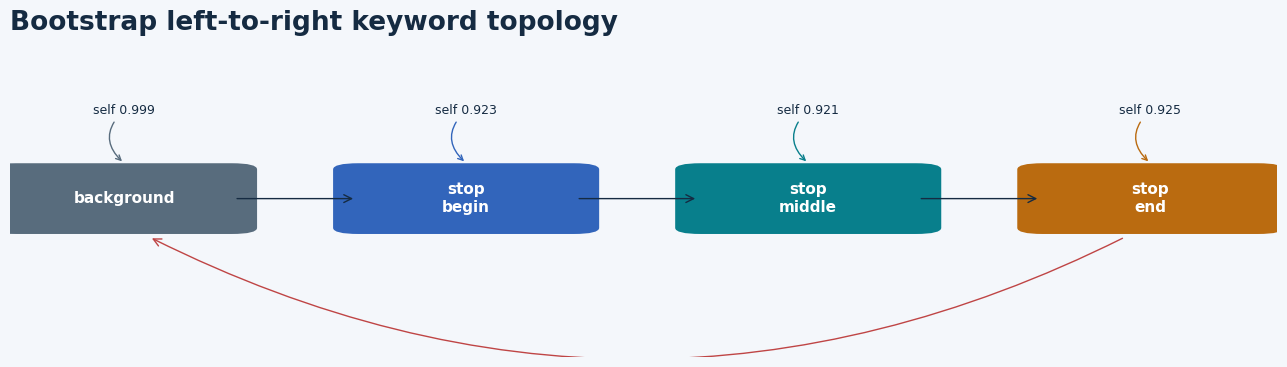

In [11]:
INK,MUTED,BLUE,TEAL,AMBER,RED="#152b42","#586c7d","#3265bb","#087f8c","#ba6b10","#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb","axes.facecolor":"white","font.size":11})
fig,ax=plt.subplots(figsize=(13,3.8)); ax.axis("off"); positions=[.09,.36,.63,.9]; colors=[MUTED,BLUE,TEAL,AMBER]
for x,label,color in zip(positions,states,colors):
    ax.add_patch(FancyBboxPatch((x-.085,.42),.17,.19,boxstyle="round,pad=.02",fc=color,ec="none",transform=ax.transAxes))
    ax.text(x,.515,label.replace("_","\n"),ha="center",va="center",color="white",weight="bold",transform=ax.transAxes)
for i in range(3):
    ax.add_patch(FancyArrowPatch((positions[i]+.087,.515),(positions[i+1]-.087,.515),arrowstyle="->",mutation_scale=14,color=INK,transform=ax.transAxes))
for i,x in enumerate(positions):
    ax.annotate(f"self {transition[i,i]:.3f}",(x,.63),(x,.79),xycoords=ax.transAxes,ha="center",arrowprops={"arrowstyle":"->","connectionstyle":"arc3,rad=.55","color":colors[i]},color=INK,fontsize=9)
ax.add_patch(FancyArrowPatch((positions[3]-.02,.39),(positions[0]+.02,.39),arrowstyle="->",connectionstyle="arc3,rad=-.25",mutation_scale=14,color=RED,transform=ax.transAxes))
ax.set_title("Bootstrap left-to-right keyword topology",loc="left",fontsize=19,weight="bold",color=INK,pad=14)
fig.tight_layout(); figures=reports/"figures"; figures.mkdir(parents=True,exist_ok=True)
fig.savefig(figures/"10_hmm_topology.png",dpi=170,bbox_inches="tight"); fig.savefig(figures/"10_hmm_topology.svg",bbox_inches="tight"); plt.show()

## 7. Inspect one alignment in audio, spectral, and state space

Frame $t$ is plotted at its right edge

$$\tau_t=\frac{W+tH}{f_s}.$$

The VAD boundary and state colors should approximately follow the spoken word. This visual check does not replace a manual alignment audit.

In [12]:
positive=[row for row in aligned if row["split"]=="train" and row["is_keyword"] and not row["is_augmented"]]
positive.sort(key=lambda row:(row["speech_end_frame"]-row["speech_start_frame"],row["id"]))
example=positive[len(positive)//2]; audio,_=read_audio(root/example["audio_path"])
features=np.load(root/example["feature_path"]); labels=np.load(root/example["alignment_path"])
levels=frame_energy_db(audio[:,0]); frame_times=(cfg["window_samples"]+np.arange(len(labels))*cfg["hop_samples"])/cfg["sample_rate"]
start,end=example["speech_start_frame"],example["speech_end_frame"]

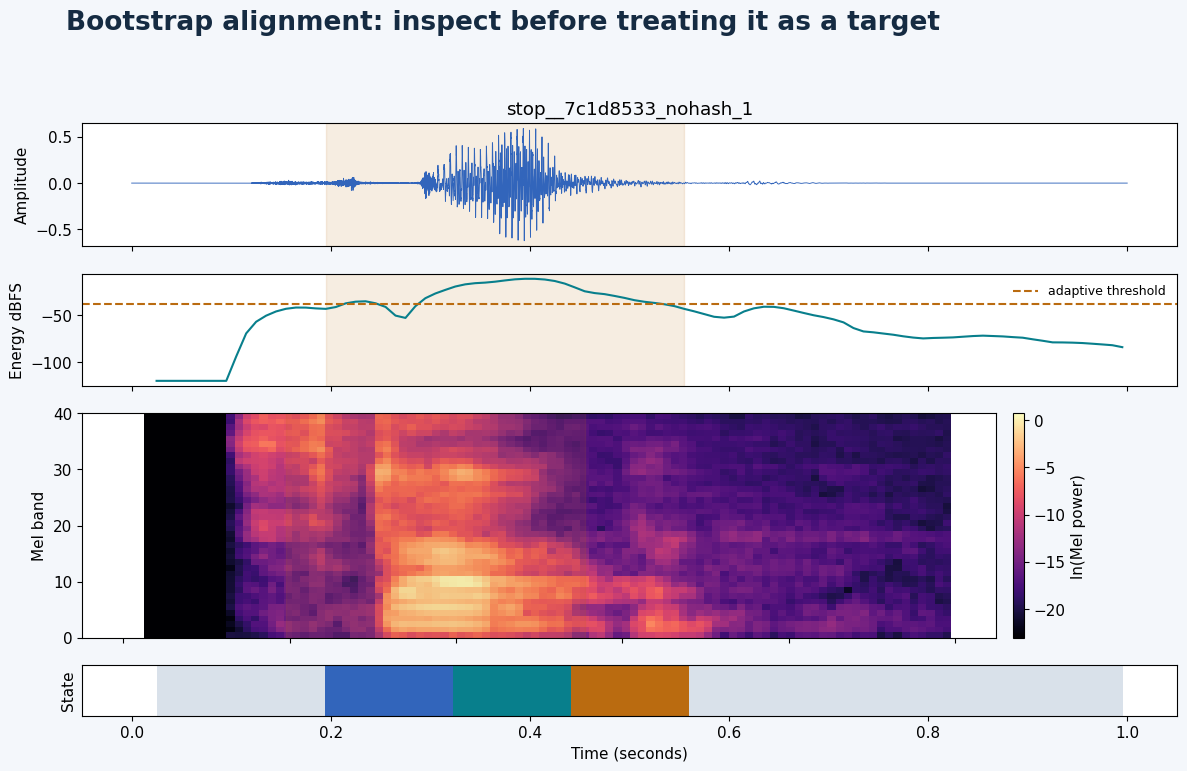

In [13]:
fig,axes=plt.subplots(4,1,figsize=(12,8),sharex=True,gridspec_kw={"height_ratios":[1.1,1,2,.45]})
time=np.arange(len(audio))/cfg["sample_rate"]; axes[0].plot(time,audio[:,0],color=BLUE,lw=.65); axes[0].set(ylabel="Amplitude",title=example["id"])
axes[1].plot(frame_times,levels,color=TEAL); axes[1].axhline(example["vad_threshold_dbfs"],color=AMBER,ls="--",label="adaptive threshold"); axes[1].set(ylabel="Energy dBFS"); axes[1].legend(frameon=False,fontsize=9)
extent=[frame_times[0],frame_times[-1],0,cfg["mel_bands"]]; image=axes[2].imshow(features.T,origin="lower",aspect="auto",extent=extent,cmap="magma"); axes[2].set(ylabel="Mel band"); fig.colorbar(image,ax=axes[2],label="ln(Mel power)",pad=.015)
cmap=ListedColormap(["#d9e1ea",BLUE,TEAL,AMBER]); axes[3].imshow(labels[None,:],aspect="auto",extent=[frame_times[0],frame_times[-1],0,1],cmap=cmap,vmin=0,vmax=3,interpolation="nearest"); axes[3].set(yticks=[],xlabel="Time (seconds)",ylabel="State")
for ax in axes[:3]: ax.axvspan(frame_times[start],frame_times[end],color=AMBER,alpha=.12)
fig.suptitle("Bootstrap alignment: inspect before treating it as a target",x=.06,ha="left",fontsize=19,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.94)); fig.savefig(figures/"10_bootstrap_alignment.png",dpi=170,bbox_inches="tight"); fig.savefig(figures/"10_bootstrap_alignment.svg",bbox_inches="tight"); plt.show()
display(Audio(filename=str(root/example["audio_path"])))

## 8. Automated alignment acceptance checks

The checks establish structural consistency only. They cannot prove that a boundary is linguistically correct.

In [14]:
alignment_by_id={row["id"]:np.load(root/row["alignment_path"]) for row in aligned}
checks={
    "one_label_per_feature_frame":all(len(alignment_by_id[r["id"]])==r["feature_frames"] for r in aligned),
    "labels_in_declared_state_set":all(set(np.unique(alignment_by_id[r["id"]])).issubset(range(len(states))) for r in aligned),
    "negative_rows_are_background":all(np.all(alignment_by_id[r["id"]]==0) for r in aligned if not r["is_keyword"]),
    "positive_rows_contain_three_keyword_states":all(set(np.unique(alignment_by_id[r["id"]]))>={1,2,3} for r in aligned if r["is_keyword"]),
    "augmented_rows_inherit_parent_alignment":all(np.array_equal(alignment_by_id[r["id"]],alignment_by_id[r["parent_id"]]) for r in aligned if r["is_augmented"]),
    "transition_rows_sum_to_one":bool(np.allclose(transition.sum(axis=1),1)),
    "forbidden_transitions_have_zero_probability":bool(np.all(transition[~mask]==0)),
}

In [15]:
durations=np.array([r["speech_end_frame"]-r["speech_start_frame"]+1 for r in aligned if r["is_keyword"] and not r["is_augmented"]])
qa={"bootstrap_alignment_pass":bool(all(checks.values())),"checks":checks,
    "aligned_rows":len(aligned),"original_positive_alignments":len(durations),
    "vad_fallbacks":sum(r["vad_fallback"] for r in aligned if not r["is_augmented"]),
    "active_frames":{"min":int(durations.min()),"median":float(np.median(durations)),"max":int(durations.max())},
    "label_status":"bootstrap_pseudo_label_not_human_verified",
    "next_step":"Review boundaries, then train the DNN frame classifier."}
(reports/"bootstrap_alignment_qa.json").write_text(json.dumps(qa,indent=2)+"\n")
display([{"check":name,"result":"PASS" if passed else "FAIL"} for name,passed in checks.items()]); display(qa)
if not qa["bootstrap_alignment_pass"]: raise RuntimeError("Bootstrap alignment QA failed")

[{'check': 'one_label_per_feature_frame', 'result': 'PASS'},
 {'check': 'labels_in_declared_state_set', 'result': 'PASS'},
 {'check': 'negative_rows_are_background', 'result': 'PASS'},
 {'check': 'positive_rows_contain_three_keyword_states', 'result': 'PASS'},
 {'check': 'augmented_rows_inherit_parent_alignment', 'result': 'PASS'},
 {'check': 'transition_rows_sum_to_one', 'result': 'PASS'},
 {'check': 'forbidden_transitions_have_zero_probability', 'result': 'PASS'}]

{'bootstrap_alignment_pass': True,
 'checks': {'one_label_per_feature_frame': True,
  'labels_in_declared_state_set': True,
  'negative_rows_are_background': True,
  'positive_rows_contain_three_keyword_states': True,
  'augmented_rows_inherit_parent_alignment': True,
  'transition_rows_sum_to_one': True,
  'forbidden_transitions_have_zero_probability': True},
 'aligned_rows': 14330,
 'original_positive_alignments': 996,
 'vad_fallbacks': 0,
 'active_frames': {'min': 9, 'median': 37.0, 'max': 98},
 'label_status': 'bootstrap_pseudo_label_not_human_verified',
 'next_step': 'Review boundaries, then train the DNN frame classifier.'}

## Interpretation and next action

This notebook provides usable **initial targets** for an experiment, with explicit lineage and QA. It does not solve alignment:

- Energy VAD can miss quiet consonants or include noise.
- Uniform thirds are not phoneme boundaries.
- Validation and test alignments are pseudo-labels, not an independent frame-level reference.
- The current corpus still cannot measure false triggers per hour.

Before trusting model metrics, listen to and review a stratified sample of boundaries. The next implementation stage is **11 · DNN frame classifier**, trained on original and augmented training rows while keeping validation/test frozen.